In [41]:
# Importing required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [42]:
import os

# Display files available in the Colab working directory
files = os.listdir('/content')

print("Files available in Colab:")
for file in files:
    print(file)

Files available in Colab:
.config
fraudTrain.csv
sample_data


In [43]:
import pandas as pd

# Load the training dataset
df = pd.read_csv('/content/fraudTrain.csv')

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [44]:
df.head()

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,...,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,...,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,...,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,...,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,...,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [45]:
# Check the number of rows and columns

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 1296675
Number of columns: 23


In [46]:
# Display all column names

print("Dataset Columns:")
print(df.columns.tolist())

Dataset Columns:
['Unnamed: 0', 'trans_date_trans_time', 'cc_num', 'merchant', 'category', 'amt', 'first', 'last', 'gender', 'street', 'city', 'state', 'zip', 'lat', 'long', 'city_pop', 'job', 'dob', 'trans_num', 'unix_time', 'merch_lat', 'merch_long', 'is_fraud']


In [47]:
# Understand the data types and non-null values

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1296675 entries, 0 to 1296674
Data columns (total 23 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   Unnamed: 0             1296675 non-null  int64  
 1   trans_date_trans_time  1296675 non-null  object 
 2   cc_num                 1296675 non-null  int64  
 3   merchant               1296675 non-null  object 
 4   category               1296675 non-null  object 
 5   amt                    1296675 non-null  float64
 6   first                  1296675 non-null  object 
 7   last                   1296675 non-null  object 
 8   gender                 1296675 non-null  object 
 9   street                 1296675 non-null  object 
 10  city                   1296675 non-null  object 
 11  state                  1296675 non-null  object 
 12  zip                    1296675 non-null  int64  
 13  lat                    1296675 non-null  float64
 14  long              

In [48]:
# Count missing values in each column

df.isnull().sum()

,0
Unnamed: 0,0
trans_date_trans_time,0
cc_num,0
merchant,0
category,0
amt,0
first,0
last,0
gender,0
street,0


In [49]:
# Count rows that contain at least one missing value
missing_rows = df[df.isnull().any(axis=1)]

print("Number of rows with missing values:", len(missing_rows))

# Display those rows
missing_rows

Number of rows with missing values: 0


,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud


In [50]:
# Remove rows containing missing values
df = df.dropna().copy()

print("Dataset after removing missing values:")
print("Rows and columns:", df.shape)

print("\nTotal missing values:", df.isnull().sum().sum())

Dataset after removing missing values:
Rows and columns: (1296675, 23)

Total missing values: 0


In [51]:
# Count duplicate rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)


Number of duplicate rows: 0


In [52]:
# Count legitimate and fraudulent transactions
fraud_counts = df['is_fraud'].value_counts()

print("Transaction Distribution:")
print(fraud_counts)

Transaction Distribution:
is_fraud
0    1289169
1       7506
Name: count, dtype: int64


In [53]:
# Calculate percentage of each transaction type
fraud_percentage = df['is_fraud'].value_counts(normalize=True) * 100

print("Transaction Percentage:")
print(fraud_percentage)

Transaction Percentage:
is_fraud
0    99.421135
1     0.578865
Name: proportion, dtype: float64


In [54]:
# Check the data types of all columns
print(df.dtypes)

Unnamed: 0                 int64
trans_date_trans_time     object
cc_num                     int64
merchant                  object
category                  object
amt                      float64
first                     object
last                      object
gender                    object
street                    object
city                      object
state                     object
zip                        int64
lat                      float64
long                     float64
city_pop                   int64
job                       object
dob                       object
trans_num                 object
unix_time                  int64
merch_lat                float64
merch_long               float64
is_fraud                   int64
dtype: object


In [55]:
# Convert transaction date and time into datetime format
df['trans_date_trans_time'] = pd.to_datetime(
    df['trans_date_trans_time']
)

# Check the updated data type
print(df['trans_date_trans_time'].dtype)

# Display the first 5 transaction dates
print(df['trans_date_trans_time'].head())

datetime64[ns]
0   2019-01-01 00:00:18
1   2019-01-01 00:00:44
2   2019-01-01 00:00:51
3   2019-01-01 00:01:16
4   2019-01-01 00:03:06
Name: trans_date_trans_time, dtype: datetime64[ns]


In [56]:
# Extract hour, day and month from transaction date

df['trans_hour'] = df['trans_date_trans_time'].dt.hour

df['trans_day'] = df['trans_date_trans_time'].dt.day

df['trans_month'] = df['trans_date_trans_time'].dt.month

# Display the new columns
print(df[['trans_date_trans_time',
          'trans_hour',
          'trans_day',
          'trans_month']].head())

  trans_date_trans_time  trans_hour  trans_day  trans_month
0   2019-01-01 00:00:18           0          1            1
1   2019-01-01 00:00:44           0          1            1
2   2019-01-01 00:00:51           0          1            1
3   2019-01-01 00:01:16           0          1            1
4   2019-01-01 00:03:06           0          1            1


In [57]:
# Display all available columns
print("Total columns:", len(df.columns))

for column in df.columns:
    print(column)

Total columns: 26
Unnamed: 0
trans_date_trans_time
cc_num
merchant
category
amt
first
last
gender
street
city
state
zip
lat
long
city_pop
job
dob
trans_num
unix_time
merch_lat
merch_long
is_fraud
trans_hour
trans_day
trans_month


In [58]:
# Select useful features for fraud detection

selected_columns = [
    'merchant',
    'category',
    'amt',
    'gender',
    'city',
    'state',
    'lat',
    'long',
    'city_pop',
    'job',
    'merch_lat',
    'merch_long',
    'trans_hour',
    'trans_day',
    'trans_month',
    'is_fraud'
]

model_df = df[selected_columns].copy()

# Display the selected dataset information
print("Selected dataset shape:", model_df.shape)

print("\nSelected columns:")
print(model_df.columns.tolist())

print("\nFirst 5 records:")
display(model_df.head())

Selected dataset shape: (1296675, 16)

Selected columns:
['merchant', 'category', 'amt', 'gender', 'city', 'state', 'lat', 'long', 'city_pop', 'job', 'merch_lat', 'merch_long', 'trans_hour', 'trans_day', 'trans_month', 'is_fraud']

First 5 records:


,merchant,category,amt,gender,city,state,lat,long,city_pop,job,merch_lat,merch_long,trans_hour,trans_day,trans_month,is_fraud
0,"fraud_Rippin, Kub and Mann",misc_net,4.97,F,Moravian Falls,NC,36.0788,-81.1781,3495,"Psychologist, counselling",36.011293,-82.048315,0,1,1,0
1,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,F,Orient,WA,48.8878,-118.2105,149,Special educational needs teacher,49.159047,-118.186462,0,1,1,0
2,fraud_Lind-Buckridge,entertainment,220.11,M,Malad City,ID,42.1808,-112.2620,4154,Nature conservation officer,43.150704,-112.154481,0,1,1,0
3,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,M,Boulder,MT,46.2306,-112.1138,1939,Patent attorney,47.034331,-112.561071,0,1,1,0
4,fraud_Keeling-Crist,misc_pos,41.96,M,Doe Hill,VA,38.4207,-79.4629,99,Dance movement psychotherapist,38.674999,-78.632459,0,1,1,0


In [59]:
# Check the number of unique values in categorical columns

categorical_columns = [
    'merchant',
    'category',
    'gender',
    'city',
    'state',
    'job'
]

for column in categorical_columns:
    print(column, ":", model_df[column].nunique(), "unique values")

merchant : 693 unique values
category : 14 unique values
gender : 2 unique values
city : 894 unique values
state : 51 unique values
job : 494 unique values


In [60]:
print("Target data type:", model_df['is_fraud'].dtype)

print("\nTarget values:")
print(model_df['is_fraud'].unique())

Target data type: int64

Target values:
[0 1]


In [61]:
# Convert target variable from float to integer

model_df['is_fraud'] = model_df['is_fraud'].astype(int)

# Verify the conversion
print("Target data type:", model_df['is_fraud'].dtype)
print("Target values:", model_df['is_fraud'].unique())

Target data type: int64
Target values: [0 1]


In [62]:
from sklearn.model_selection import train_test_split

# Separate input features and target variable
X = model_df.drop('is_fraud', axis=1)
y = model_df['is_fraud']

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (1037340, 15)
Testing features: (259335, 15)

Training target: (1037340,)
Testing target: (259335,)


In [63]:
# Check fraud distribution in training and testing data

print("Training fraud distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting fraud distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training fraud distribution:
is_fraud
0    99.421116
1     0.578884
Name: proportion, dtype: float64

Testing fraud distribution:
is_fraud
0    99.421212
1     0.578788
Name: proportion, dtype: float64


In [64]:
# Display categorical columns in training data

categorical_columns = X_train.select_dtypes(
    include=['object']
).columns.tolist()

print("Categorical columns:")
print(categorical_columns)

print("\nNumber of categorical columns:",
      len(categorical_columns))

Categorical columns:
['merchant', 'category', 'gender', 'city', 'state', 'job']

Number of categorical columns: 6


In [65]:
import pandas as pd

# Create copies of training and testing data
X_train_encoded = X_train.copy()
X_test_encoded = X_test.copy()

# Columns for One-Hot Encoding
onehot_columns = ['category', 'gender', 'state']

# Columns for Frequency Encoding
frequency_columns = ['merchant', 'city', 'job']

# Apply Frequency Encoding
for column in frequency_columns:

    # Calculate frequencies using training data only
    frequency_map = X_train[column].value_counts(normalize=True)

    # Apply the same mapping to training and testing data
    X_train_encoded[column] = X_train[column].map(frequency_map).fillna(0)
    X_test_encoded[column] = X_test[column].map(frequency_map).fillna(0)

# Apply One-Hot Encoding
X_train_encoded = pd.get_dummies(
    X_train_encoded,
    columns=onehot_columns,
    dtype=int
)

X_test_encoded = pd.get_dummies(
    X_test_encoded,
    columns=onehot_columns,
    dtype=int
)

# Ensure training and testing have identical columns
X_test_encoded = X_test_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

# Display results
print("Training data shape:", X_train_encoded.shape)
print("Testing data shape:", X_test_encoded.shape)

print("\nAre training and testing columns identical?",
      list(X_train_encoded.columns) == list(X_test_encoded.columns))

Training data shape: (1037340, 79)
Testing data shape: (259335, 79)

Are training and testing columns identical? True


In [66]:
print("Training distribution before SMOTE:")
print(y_train.value_counts())

print("\nFraud percentage before SMOTE:")
print(y_train.value_counts(normalize=True) * 100)

Training distribution before SMOTE:
is_fraud
0    1031335
1       6005
Name: count, dtype: int64

Fraud percentage before SMOTE:
is_fraud
0    99.421116
1     0.578884
Name: proportion, dtype: float64


In [67]:
# Create copies of the original training and testing data
X_train_smotenc = X_train.copy()
X_test_smotenc = X_test.copy()

print("Training data shape:", X_train_smotenc.shape)
print("Testing data shape:", X_test_smotenc.shape)

print("\nCategorical columns:")
print(X_train_smotenc.select_dtypes(include=['object']).columns.tolist())

Training data shape: (1037340, 15)
Testing data shape: (259335, 15)

Categorical columns:
['merchant', 'category', 'gender', 'city', 'state', 'job']


In [68]:
categorical_columns = X_train_smotenc.select_dtypes(
    include=['object']
).columns.tolist()

categorical_indices = [
    X_train_smotenc.columns.get_loc(column)
    for column in categorical_columns
]

print("Categorical columns:", categorical_columns)
print("Categorical column positions:", categorical_indices)


Categorical columns: ['merchant', 'category', 'gender', 'city', 'state', 'job']
Categorical column positions: [0, 1, 3, 4, 5, 9]


In [69]:
from sklearn.preprocessing import OrdinalEncoder

encoder = OrdinalEncoder(
    handle_unknown='use_encoded_value',
    unknown_value=-1
)

X_train_smotenc[categorical_columns] = encoder.fit_transform(
    X_train_smotenc[categorical_columns]
)

X_test_smotenc[categorical_columns] = encoder.transform(
    X_test_smotenc[categorical_columns]
)

print("Training data after encoding:")
display(X_train_smotenc.head())

print("\nTraining data types:")
print(X_train_smotenc.dtypes)

Training data after encoding:


,merchant,category,amt,gender,city,state,lat,long,city_pop,job,merch_lat,merch_long,trans_hour,trans_day,trans_month
509059,600.0,3.0,51.71,0.0,322.0,34.0,44.6087,-74.9732,69,74.0,44.785928,-74.659301,3,9,8
395295,151.0,0.0,13.78,0.0,501.0,43.0,31.9290,-97.6443,2526,340.0,31.414028,-98.152203,19,29,6
536531,341.0,12.0,961.26,0.0,171.0,47.0,48.3400,-122.3456,85,390.0,49.118546,-122.622065,14,18,8
271001,493.0,5.0,43.68,1.0,831.0,4.0,40.0235,-120.7986,128,143.0,39.528098,-121.059990,21,13,5
532788,644.0,0.0,33.08,0.0,615.0,24.0,38.3511,-91.4867,6703,308.0,39.213785,-92.188153,14,17,8



Training data types:
merchant       float64
category       float64
amt            float64
gender         float64
city           float64
state          float64
lat            float64
long           float64
city_pop         int64
job            float64
merch_lat      float64
merch_long     float64
trans_hour       int32
trans_day        int32
trans_month      int32
dtype: object


In [70]:
categorical_columns = [
    'merchant', 'category', 'gender', 'city', 'state', 'job'
]

categorical_indices = [
    X_train_smotenc.columns.get_loc(column)
    for column in categorical_columns
]

print("Categorical columns:", categorical_columns)
print("Categorical indices:", categorical_indices)

Categorical columns: ['merchant', 'category', 'gender', 'city', 'state', 'job']
Categorical indices: [0, 1, 3, 4, 5, 9]


In [71]:
print("X_train_smotenc exists:", 'X_train_smotenc' in globals())
print("X_test_smotenc exists:", 'X_test_smotenc' in globals())
print("y_train exists:", 'y_train' in globals())
print("SMOTENC indices:", categorical_indices)

X_train_smotenc exists: True
X_test_smotenc exists: True
y_train exists: True
SMOTENC indices: [0, 1, 3, 4, 5, 9]


In [72]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced_subsample',
    random_state=42,
    n_jobs=-1
)

In [73]:
print("Training features:", X_train_encoded.shape)
print("Testing features:", X_test_encoded.shape)

print("\nTraining target:")
print(y_train.value_counts())

print("\nTesting target:")
print(y_test.value_counts())

Training features: (1037340, 79)
Testing features: (259335, 79)

Training target:
is_fraud
0    1031335
1       6005
Name: count, dtype: int64

Testing target:
is_fraud
0    257834
1      1501
Name: count, dtype: int64


In [74]:
print("Original dataset shape:", df.shape)
print("\nModel dataset shape:", model_df.shape)

print("\nFraud distribution:")
print(model_df['is_fraud'].value_counts())

print("\nFraud percentage:")
print(model_df['is_fraud'].value_counts(normalize=True) * 100)

Original dataset shape: (1296675, 26)

Model dataset shape: (1296675, 16)

Fraud distribution:
is_fraud
0    1289169
1       7506
Name: count, dtype: int64

Fraud percentage:
is_fraud
0    99.421135
1     0.578865
Name: proportion, dtype: float64


In [75]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training data: (1037340, 15)
Testing data: (259335, 15)

Training target distribution:
is_fraud
0    1031335
1       6005
Name: count, dtype: int64

Testing target distribution:
is_fraud
0    257834
1      1501
Name: count, dtype: int64


In [76]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced_subsample',
    random_state=42,
    n_jobs=-1
)

print("Random Forest model created successfully!")

Random Forest model created successfully!


In [78]:
# Train the Random Forest model
rf_model.fit(X_train_encoded, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [79]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Predict on unseen testing data
y_pred = rf_model.predict(X_test_encoded)

# Calculate evaluation metrics
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.9980989839396919
Precision: 0.9754716981132076
Recall: 0.6888740839440373
F1 Score: 0.8074970714564623

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    257834
           1       0.98      0.69      0.81      1501

    accuracy                           1.00    259335
   macro avg       0.99      0.84      0.90    259335
weighted avg       1.00      1.00      1.00    259335



Confusion Matrix:
[[257808     26]
 [   467   1034]]


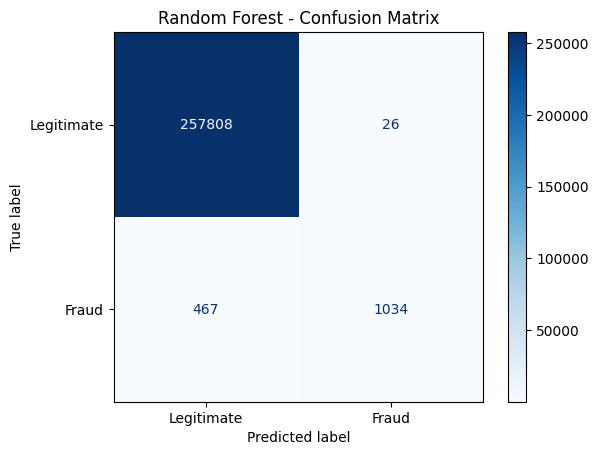

In [80]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Legitimate', 'Fraud']
)

disp.plot(cmap='Blues')
plt.title("Random Forest - Confusion Matrix")
plt.show()

In [81]:
# Get fraud probabilities
y_prob = rf_model.predict_proba(X_test_encoded)[:, 1]

# Apply a lower prediction threshold
new_threshold = 0.30
y_pred_new = (y_prob >= new_threshold).astype(int)

from sklearn.metrics import classification_report

print("Classification Report at Threshold 0.30:")
print(classification_report(y_test, y_pred_new))

Classification Report at Threshold 0.30:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    257834
           1       0.91      0.80      0.85      1501

    accuracy                           1.00    259335
   macro avg       0.95      0.90      0.92    259335
weighted avg       1.00      1.00      1.00    259335



Confusion Matrix at Threshold 0.30:
[[257713    121]
 [   307   1194]]


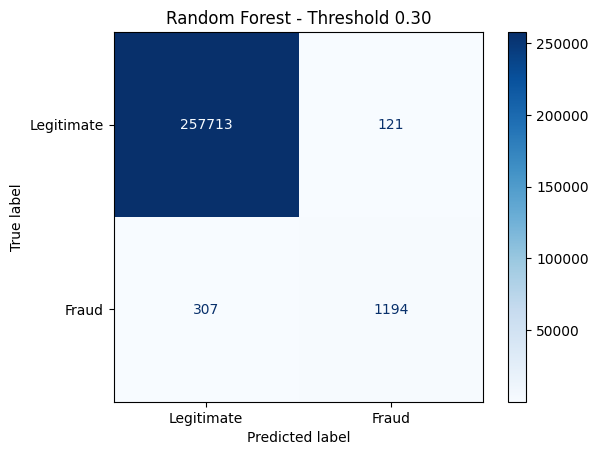

In [82]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_new = confusion_matrix(y_test, y_pred_new)

print("Confusion Matrix at Threshold 0.30:")
print(cm_new)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_new,
    display_labels=['Legitimate', 'Fraud']
)

disp.plot(cmap='Blues')
plt.title("Random Forest - Threshold 0.30")
plt.show()

In [83]:
import pandas as pd

comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score'],
    'Threshold 0.50': [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred)
    ],
    'Threshold 0.30': [
        accuracy_score(y_test, y_pred_new),
        precision_score(y_test, y_pred_new),
        recall_score(y_test, y_pred_new),
        f1_score(y_test, y_pred_new)
    ]
})

display(comparison.round(4))

,Metric,Threshold 0.50,Threshold 0.30
0,Accuracy,0.9981,0.9983
1,Precision,0.9755,0.9080
2,Recall,0.6889,0.7955
3,F1 Score,0.8075,0.8480


In [84]:
import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.DataFrame({
    'Feature': X_train_encoded.columns,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print("Top 15 Important Features:")
display(feature_importance.head(15))

Top 15 Important Features:


,Feature,Importance
1,amt,0.457065
9,trans_hour,0.162497
2,city,0.046605
0,merchant,0.040691
6,job,0.024276
23,category_shopping_net,0.021589
16,category_grocery_pos,0.018568
8,merch_long,0.018515
7,merch_lat,0.018477
5,city_pop,0.018069


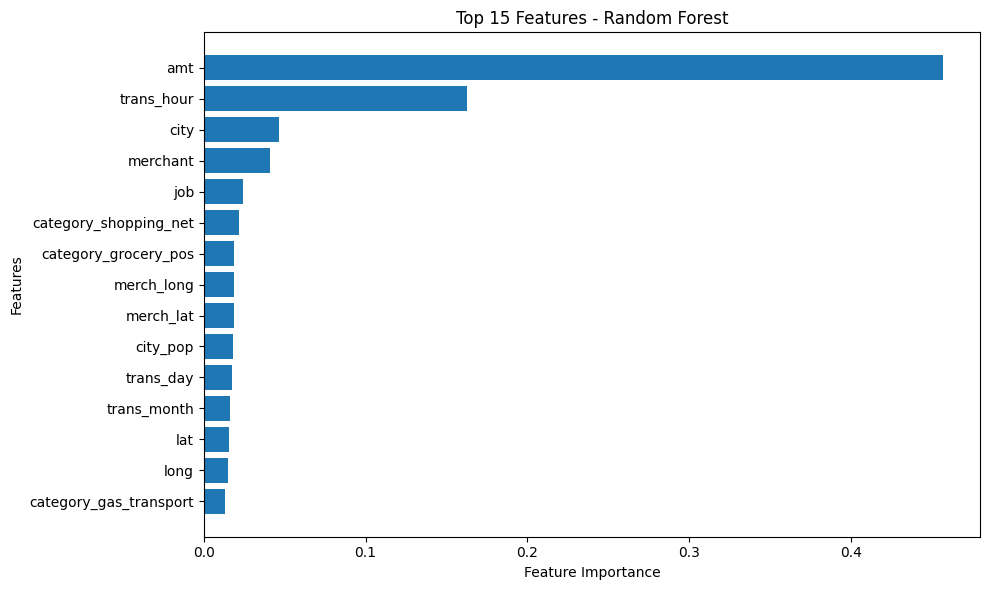

In [85]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance.head(15)['Feature'][::-1],
    feature_importance.head(15)['Importance'][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 15 Features - Random Forest")
plt.tight_layout()
plt.show()

In [86]:
import joblib

joblib.dump(rf_model, 'credit_card_fraud_model.pkl')

print("Model saved successfully!")

Model saved successfully!


In [87]:
import joblib

model_config = {
    'threshold': 0.30,
    'features': X_train_encoded.columns.tolist()
}

joblib.dump(model_config, 'model_config.pkl')

print("Model configuration saved successfully!")

Model configuration saved successfully!


In [88]:
from google.colab import files

files.download('credit_card_fraud_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [89]:
files.download('model_config.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Credit Card Fraud Detection

### Machine Learning Project Using Python

**Objective:** To analyze credit card transactions and develop a machine learning model that identifies potentially fraudulent transactions.

**Technologies:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn.
